# 11 · ANOVA and ANCOVA as linear models

ANOVA compares group means by separating between-group variation from within-group variation. ANCOVA adds numerical covariates so groups can be compared at common covariate values. Both fit naturally into the regression framework, with assumptions and contrasts that must match the question.

```mermaid
flowchart LR
    A[Several groups] --> B[One mean versus group means]
    B --> C[ANOVA F-test]
    C --> D[Planned contrasts or adjusted pairwise tests]
    A --> E[Add a numerical covariate]
    E --> F[ANCOVA: common or interacting slopes]
    F --> G[Conditional contrasts and diagnostics]
```

**Learning route:** variance decomposition → omnibus test → follow-up contrasts → covariate adjustment → interaction. Prerequisites: Chapters [7](../07_Multiple_Regression/07_Multiple_Regression.md), [8](../08_T-test_for_Testing_the_Differences/08_T-test_for_Testing_the_Differences.md), and [10](../10_P-Values_Pitfalls/10_P-Values_Pitfalls.md).

## 1. ANOVA tests one joint hypothesis

For $g$ groups, the one-way model is $Y_{ij}=\mu_j+\varepsilon_{ij}$, where $i$ indexes observations and $j$ groups. The classical assumptions are independent normal errors with common variance $\sigma^2$. The null is

$$H_0:\mu_1=\mu_2=\cdots=\mu_g.$$

The alternative is that at least one population mean differs. It does not claim every pair differs, identify the largest mean with certainty, or establish a cause. ANOVA is an **omnibus** test: it combines all mean differences into one question.

With an intercept and $g-1$ group indicators, this is ordinary regression. Its reduced model has one common mean; the full model has $g$ group means. Both are fit to the same observations. For $g=2$, the classical ANOVA F-test equals the square of the pooled two-sample t-test.

## 2. Why analyzing variance can compare means

Let $n_j$ be group size, $N=\sum_jn_j$, $\bar y_j$ the group mean, and $\bar y$ the grand mean weighted by group sizes. Define

$$SS_W=\sum_j\sum_i(y_{ij}-\bar y_j)^2,$$

$$SS_B=\sum_j n_j(\bar y_j-\bar y)^2,\qquad
SS_T=\sum_j\sum_i(y_{ij}-\bar y)^2.$$

The identity $SS_T=SS_B+SS_W$ follows by expanding $y_{ij}-\bar y=(y_{ij}-\bar y_j)+(\bar y_j-\bar y)$; cross-terms vanish because each group's residuals sum to zero.

Under equal population means, both $MS_B=SS_B/(g-1)$ and $MS_W=SS_W/(N-g)$ estimate the same noise variance. Under unequal means, $MS_B$ tends to grow because it also reflects separation between group means. Their ratio is

$$F=\frac{MS_B}{MS_W}\sim F_{g-1,N-g}\quad\text{under }H_0.$$

This is the nested-model formula from Chapter 7: $SS_W$ is full-model RSS and $SS_B$ is the reduction from the mean-only model.

## 3. A complete hand-worked ANOVA

Three fictional packing layouts produce these independent completion times:

| Layout | Times, minutes | Mean | Within-group squared deviations |
|---|---|---:|---:|
| A | 4, 5, 6, 5 | 5 | 2 |
| B | 6, 7, 8, 7 | 7 | 2 |
| C | 8, 9, 10, 9 | 9 | 2 |

The grand mean is 7. Within-group SS is $2+2+2=6$, and between-group SS is $4(5-7)^2+4(7-7)^2+4(9-7)^2=32$. Therefore total SS is 38.

| Source | SS | df | Mean square | F |
|---|---:|---:|---:|---:|
| Between layouts | 32 | 2 | 16 | 24 |
| Within layouts | 6 | 9 | $2/3$ | |
| Total | 38 | 11 | | |

The p-value is the upper tail of $F_{2,9}$ beyond 24, about 0.000247. We reject equal population means under the model. The result says some means differ; follow-up contrasts answer which ones.

![Layout observations and the common-mean and group-mean models](figure/anova_groups.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '11_Anova_and_Ancova' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


,sum_sq,df,F,PR(>F)
C(layout),32.0,2.0,24.0,0.000247
Residual,6.0,9.0,NaN,NaN


eta squared: 0.8421052631578947 omega squared: 0.7931034482758621


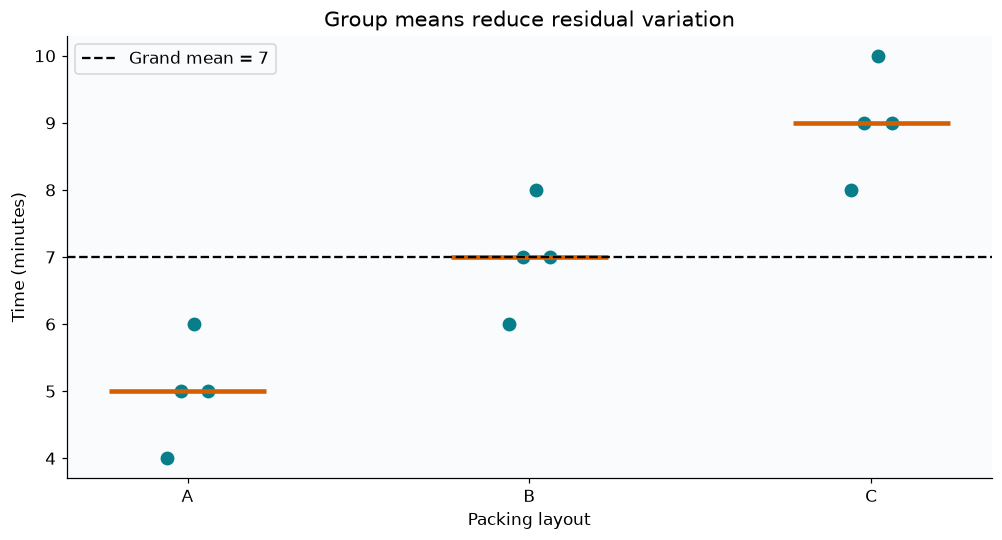

In [2]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.multicomp import pairwise_tukeyhsd
groups = {"A":np.array([4,5,6,5.]),"B":np.array([6,7,8,7.]),"C":np.array([8,9,10,9.])}
data = pd.DataFrame([(g,v) for g,values in groups.items() for v in values],columns=["layout","time"])
grand = data.time.mean()
ssw = sum(np.sum((v-v.mean())**2) for v in groups.values())
ssb = sum(len(v)*(v.mean()-grand)**2 for v in groups.values())
sst = np.sum((data.time-grand)**2)
N,g = len(data),len(groups)
mse = ssw/(N-g)
f_stat = (ssb/(g-1))/mse
model = smf.ols("time ~ C(layout)",data=data).fit()
assert np.isclose(ssw,6) and np.isclose(ssb,32) and np.isclose(sst,ssw+ssb)
assert np.isclose(f_stat,24) and np.isclose(f_stat,stats.f_oneway(*groups.values()).statistic)
assert np.isclose(f_stat,model.fvalue)
display(sm.stats.anova_lm(model,typ=2))
print("eta squared:",ssb/sst,"omega squared:",(ssb-(g-1)*mse)/(sst+mse))
fig, ax = plt.subplots(layout="constrained")
for i,(name,values) in enumerate(groups.items()):
    ax.scatter(i+np.array([-.06,-.02,.02,.06]),values,s=65,color=TEAL)
    ax.hlines(values.mean(),i-.23,i+.23,color=ORANGE,lw=3)
ax.axhline(grand,color="black",ls="--",label="Grand mean = 7")
ax.set(xticks=np.arange(g),xticklabels=list(groups),xlabel="Packing layout",ylabel="Time (minutes)",title="Group means reduce residual variation")
ax.legend()
save_figure(fig,"anova_groups")

One descriptive effect-size measure is $\eta^2=SS_B/SS_T=32/38\approx0.8421$, the fraction of observed squared variation accounted for by group membership. It equals the model's training $R^2$. It does not mean layout causes 84% of the variation. A bias-reduced estimator commonly reported in one-way ANOVA is

$$\omega^2=\frac{SS_B-(g-1)MS_W}{SS_T+MS_W},$$

here about 0.7931. In small noisy datasets this estimate can be negative; report the convention used if truncating it to zero. Also report group means and differences in minutes so effects remain interpretable.

## 4. Follow-up comparisons need their own error control

For all pairwise comparisons, there are $g(g-1)/2$ tests. A significant omnibus test does not generally justify unadjusted tests for every pair. Specify the family and a method such as Tukey's simultaneous all-pairs procedure or Holm-adjusted contrasts.

Under the common-variance model, a contrast between group means $j$ and $k$ has

$$SE(\bar y_j-\bar y_k)=\sqrt{MS_W(1/n_j+1/n_k)}$$

and uses the full residual df $N-g$. This pools variance across all groups, matching the ANOVA model. It differs from estimating a separate pooled variance for every pair. The notebook uses these shared-variance t contrasts and Holm correction, and also produces Tukey simultaneous intervals.

![Simultaneous intervals for pairwise layout differences](figure/pairwise_intervals.png)

,contrast,difference,SE,raw_p,Holm_p
0,B - A,2.0,0.57735,0.007115,0.014229
1,C - A,4.0,0.57735,0.000068,0.000205
2,C - B,2.0,0.57735,0.007115,0.014229


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower upper reject
------------------------------------------------
     A      B      2.0 0.0176 0.388 3.612   True
     A      C      4.0 0.0002 2.388 5.612   True
     B      C      2.0 0.0176 0.388 3.612   True
------------------------------------------------


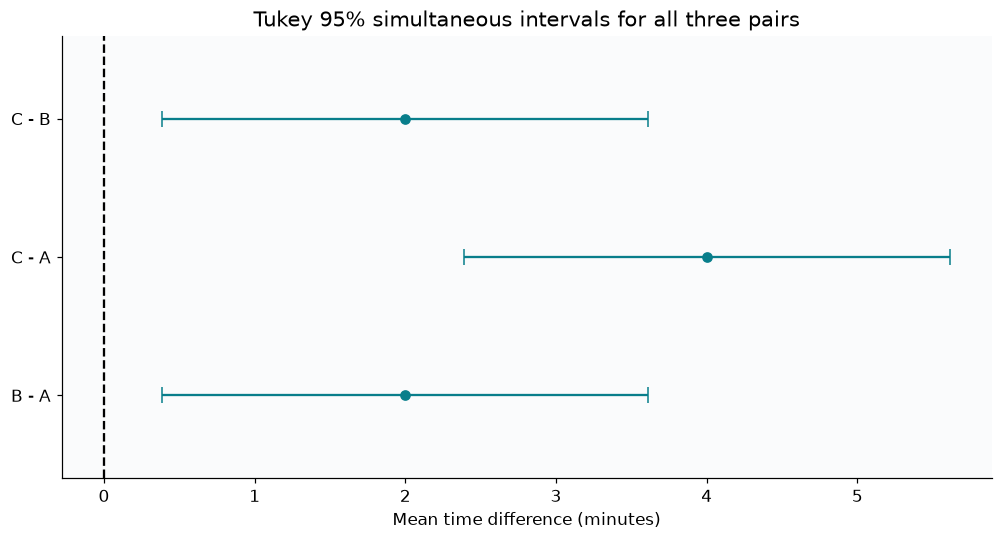

In [3]:
contrasts = []
for left,right in combinations(groups,2):
    difference = groups[right].mean()-groups[left].mean()
    se_diff = np.sqrt(mse*(1/len(groups[left])+1/len(groups[right])))
    p = 2*stats.t.sf(abs(difference/se_diff),N-g)
    contrasts.append([f"{right} - {left}",difference,se_diff,p])
comparisons = pd.DataFrame(contrasts,columns=["contrast","difference","SE","raw_p"])
comparisons["Holm_p"] = multipletests(comparisons.raw_p,method="holm")[1]
display(comparisons)
tukey = pairwise_tukeyhsd(data.time,data.layout,alpha=.05)
print(tukey)
fig, ax = plt.subplots(layout="constrained")
differences = np.array(tukey.meandiffs)
intervals = np.array(tukey.confint)
ax.errorbar(differences,np.arange(len(differences)),
            xerr=[differences-intervals[:,0],intervals[:,1]-differences],fmt="o",capsize=5,color=TEAL)
ax.axvline(0,color="black",ls="--")
ax.set(yticks=np.arange(3),yticklabels=comparisons.contrast,xlabel="Mean time difference (minutes)",
       title="Tukey 95% simultaneous intervals for all three pairs",ylim=(-.6,2.6))
save_figure(fig,"pairwise_intervals")

Planned contrasts can target a more specific question, such as one new layout versus the average of two established layouts. Coefficients of a group-mean contrast sum to zero. Not every valid planned-contrast strategy requires passing an omnibus test first; its error control should be specified directly rather than invented after seeing the ANOVA result.

## 5. ANCOVA adds a covariate

Suppose two drying methods are compared using initial moisture as a **pre-treatment** covariate. Center moisture at 20 percentage points: $x=\text{moisture}-20$. Let $z=1$ for method B and 0 for A. An additive ANCOVA is

$$Y=\beta_0+\beta_1x+\tau z+\varepsilon.$$

Both groups have slope $\beta_1$. The parameter $\tau$ is the mean B-minus-A difference at the same moisture, assumed constant throughout the range. The model has three coefficients, not four: two intercepts and one shared slope.

Our invented dataset uses moisture values 18, 19, 20, 21, 22 in **each** group, with times A = $(7,7,10,11,15)$ and B = $(2,6,7,10,10)$ minutes. The fitted model is

$$\hat y=10+2x-3z.$$

The conditional B-minus-A difference is $-3$ minutes. Because moisture is balanced between groups, the unadjusted difference is also $-3$, but controlling for moisture substantially reduces unexplained variation. Adjustment can improve precision without changing the estimated difference.

![ANCOVA compares methods at the same moisture](figure/ancova.png)

,estimate,SE,p
Intercept,10.0,0.478091,1.435164e-07
C(method)[T.B],-3.0,0.676123,3.018399e-03
x,2.0,0.239046,6.839584e-05


Unadjusted group p: 0.19053350155673301


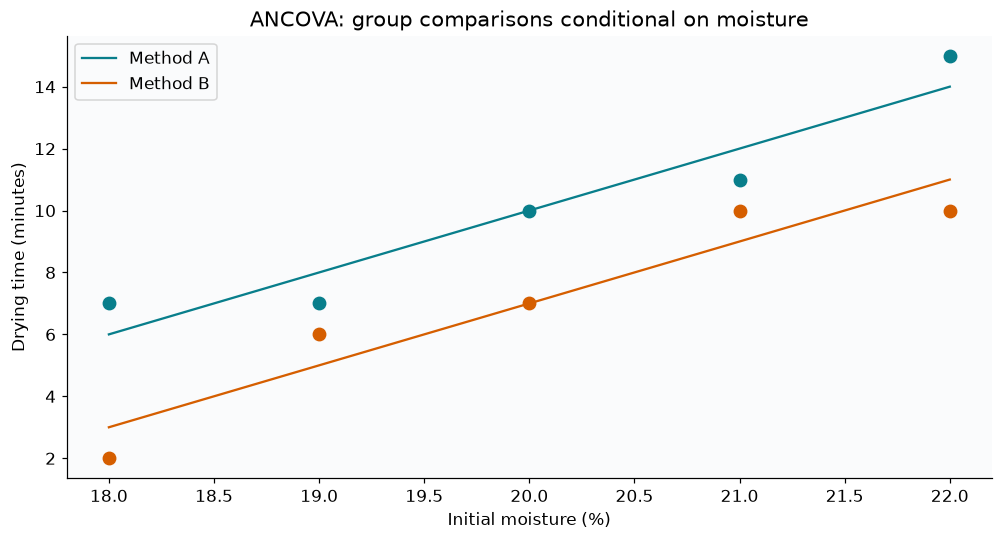

In [4]:
moisture = np.tile(np.arange(18,23,dtype=float),2)
method = np.repeat(["A","B"],5)
dry_time = np.array([7,7,10,11,15,2,6,7,10,10],dtype=float)
dry = pd.DataFrame({"moisture":moisture,"x":moisture-20,"method":method,"time":dry_time})
adjusted = smf.ols("time ~ x + C(method)",data=dry).fit()
unadjusted = smf.ols("time ~ C(method)",data=dry).fit()
covariate_only = smf.ols("time ~ x",data=dry).fit()
assert np.isclose(adjusted.params["C(method)[T.B]"],-3)
assert np.isclose(adjusted.params["x"],2) and np.isclose(adjusted.ssr,8)
display(pd.DataFrame({"estimate":adjusted.params,"SE":adjusted.bse,"p":adjusted.pvalues}))
print("Unadjusted group p:",unadjusted.pvalues["C(method)[T.B]"])
fig, ax = plt.subplots(layout="constrained")
for label,color in [("A",TEAL),("B",ORANGE)]:
    observed = dry[dry.method==label]
    ax.scatter(observed.moisture,observed.time,color=color,s=65)
    grid = np.linspace(18,22,60)
    prediction = adjusted.predict(pd.DataFrame({"x":grid-20,"method":label}))
    ax.plot(grid,prediction,color=color,label=f"Method {label}")
ax.set(xlabel="Initial moisture (%)",ylabel="Drying time (minutes)",title="ANCOVA: group comparisons conditional on moisture")
ax.legend()
save_figure(fig,"ancova")

## 6. Test the added group term, not the wrong model

To test $H_0:\tau=0$, compare the reduced model $Y\sim1+x$ with the full model $Y\sim1+x+z$. In the teaching data, $RSS_R=30.5$, $RSS_F=8$, $K_R=2$, $K_F=3$, and $N=10$. Hence

$$F=\frac{(30.5-8)/1}{8/7}=19.6875,$$

with $(1,7)$ degrees of freedom and $p\approx0.00302$. This isolates the group effect **after** accounting for the covariate. The unadjusted comparison has $p\approx0.191$ despite the same estimated difference of $-3$ minutes: adjusting for the predictive baseline covariate reduced its SE. The adjusted 95% interval is approximately $[-4.60,-1.40]$ minutes. These are deliberately constructed data illustrating precision, not a reason to search for covariates until significance appears. An overall full-model F-test against an intercept-only model instead tests both the covariate and group terms jointly.

The **partial** $R^2$ for adding group is $(RSS_R-RSS_F)/RSS_R=22.5/30.5\approx0.7377$. It is the proportion of the reduced model's residual variation removed by the added term. The full model's ordinary $R^2$ uses total variation around the grand mean and answers a different question.

In [5]:
f_partial,p_partial,df_added = adjusted.compare_f_test(covariate_only)
partial_r2 = (covariate_only.ssr-adjusted.ssr)/covariate_only.ssr
assert np.isclose(covariate_only.ssr,30.5) and np.isclose(f_partial,19.6875)
print(f"Group after moisture: F={f_partial:.4f}, p={p_partial:.6f}, df=({df_added:g},7)")
print("Partial R²:",partial_r2,"; ordinary full-model R²:",adjusted.rsquared)
display(adjusted.conf_int().rename(columns={0:"95% lower",1:"95% upper"}))

Group after moisture: F=19.6875, p=0.003018, df=(1,7)
Partial R²: 0.7377049180327869 ; ordinary full-model R²: 0.9276018099547512


,95% lower,95% upper
Intercept,8.869493,11.130507
C(method)[T.B],-4.598778,-1.401222
x,1.434747,2.565253


## 7. Check common slopes, overlap, and the estimand

An interaction model adds $\gamma xz$. It allows different moisture slopes: $\beta_1$ for A and $\beta_1+\gamma$ for B. Then the conditional difference is $\tau+\gamma x$. Evaluate that contrast at meaningful moisture levels with adequate overlap. A single group coefficient is no longer a universal adjusted effect.

Compare additive and interaction models only when the question and data support it. A nonsignificant interaction in a small sample does not prove parallel slopes. The notebook checks the extra term and then illustrates a separate, deliberately specified interaction equation.

In [6]:
interaction_fit = smf.ols("time ~ x * C(method)",data=dry).fit()
print("Comparison allowing separate slopes:",interaction_fit.compare_f_test(adjusted))
print("Do not interpret nonrejection as proof of equal population slopes.")
illustrative_x = np.array([-2,0,2])
display(pd.DataFrame({"centered_moisture":illustrative_x,
                      "specified_interaction_contrast":-3+.8*illustrative_x}))

Comparison allowing separate slopes: (np.float64(3.996802888650567e-15), np.float64(0.9999999516070595), np.float64(1.0))
Do not interpret nonrejection as proof of equal population slopes.


,centered_moisture,specified_interaction_contrast
0,-2,-4.6
1,0,-3.0
2,2,-1.4


Common covariate support is crucial: if all A observations have low moisture and all B observations high moisture, a comparison at a shared value may depend mostly on extrapolation. Adjusting for a variable affected by treatment can change the estimand or introduce bias. In observational data, adding covariates alone does not establish causality.

One-way ANOVA assumes common variance. For clearly unequal variances, especially with unequal sample sizes, Welch ANOVA or an appropriate robust model may be preferable. Repeated-measures and clustered data need corresponding designs. With multiple factors, a factorial model such as `time ~ C(layout) * C(material)` also includes interaction; in unbalanced data, different ANOVA sum-of-squares conventions test different hypotheses. Specify the actual model comparison rather than choosing a table type by habit.

## 8. Practice

1. Four groups contain five observations each. The within-group SS is 80 and between-group SS is 60. Calculate the ANOVA F and degrees of freedom.
2. Does a significant omnibus test establish that the largest sample mean differs from every other mean?
3. In $\hat y=12+0.5x-2z+0.3xz$, find the B-minus-A contrast at $x=0$ and $x=10$.
4. A reduced ANCOVA has RSS 50; adding two group indicators gives RSS 30. There are 24 observations and four full-model coefficients. Calculate partial F and partial $R^2$.
5. Why is adjusting for a measurement made after treatment potentially different from adjusting for baseline moisture?

## 9. Worked answers

1. $N=20$, $g=4$, so $F=(60/3)/(80/16)=4$, with $(3,16)$ df.
2. No. It establishes evidence against joint equality; specified contrasts and suitable multiplicity control identify particular differences.
3. The contrast is $-2+0.3x$. It is -2 at zero and +1 at ten; the estimated direction changes across the covariate range.
4. $F=[(50-30)/2]/[30/(24-4)]=20/3\approx6.667$, with $(2,20)$ df. Partial $R^2=(50-30)/50=0.4$.
5. A post-treatment measurement may be on the causal path or reflect selection caused by treatment. Conditioning on it can alter the target effect and introduce bias; baseline adjustment and post-treatment adjustment are not interchangeable.

In [7]:
assert np.isclose((60/3)/(80/16),4)
assert np.isclose(((50-30)/2)/(30/20),20/3)
print("Practice 1 p:",stats.f.sf(4,3,16))
print("Practice 4 partial R²:",(50-30)/50)

Practice 1 p: 0.02658133088196222
Practice 4 partial R²: 0.4


## References and next step

Reading connection: Starmer (2026), Chapter 11, [SQ](../Reference.md#sq-statquest). [NIST one-factor ANOVA](https://www.itl.nist.gov/div898/handbook/eda/section3/eda354.htm) supports the decomposition and assumptions. Implementations: [statsmodels ANOVA](https://www.statsmodels.org/stable/generated/statsmodels.stats.anova.anova_lm.html), [Tukey HSD](https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html). The partial-$R^2$ and interaction examples extend the reading.

Return to the [course map](../README.md), or review [the prerequisites and derivations](../AA_Prerequisite/AA_Prerequisite.md).